# Модель отклика

Прогноз доли прослушивания по истории и кандидату.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "run.py").exists():
    raise RuntimeError("Открой ноутбук из корня проекта.")
RETRAIN = False  # True — обучение; False — сохранённые результаты.
WORK = ROOT / "runs/notebooks" if RETRAIN else ROOT

def run(stage):
    subprocess.run([sys.executable, str(ROOT / "run.py"), stage,
                    "--work-dir", str(WORK)], check=True)


## Обучение

Основная RM, другой seed и вариант без истории. Checkpoint по validation RMSE. Здесь же обучается контроль продолженного next-item обучения.

In [2]:
if RETRAIN:
    run("rm")

## Результат

На 1 735 тестовых взаимодействиях RM лучше среднего прошлого отклика по RMSE, но хуже по MAE.

,model,mae,rmse,mean_prediction,mean_target,examples
0,global_mean,0.409552,0.433195,0.651797,0.670807,1735
1,item_mean,0.405382,0.432112,0.650973,0.670807,1735
2,item_mean_all_train,0.402248,0.430346,0.649491,0.670807,1735
3,history_mean,0.292580,0.380403,0.660453,0.670807,1735
4,reward,0.298197,0.363701,0.658864,0.670807,1735
5,auditor,0.304115,0.365330,0.635971,0.670807,1735
6,no_history,0.404853,0.430241,0.647229,0.670807,1735


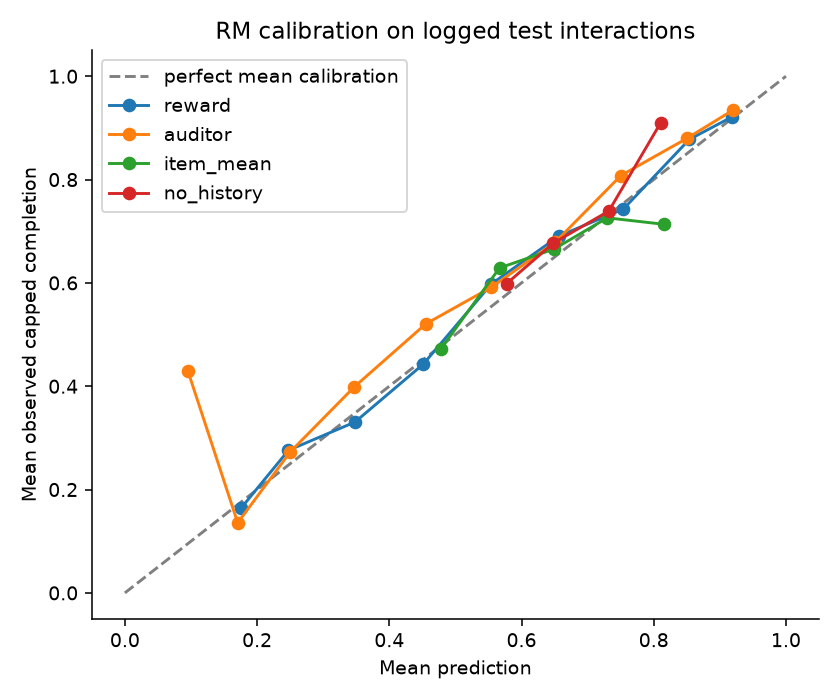

In [3]:
details_path = WORK / "results/details.json"
if details_path.exists():
    details = json.loads(details_path.read_text())
    display(pd.DataFrame([{ "model": key.split("/")[1], **value }
        for key, value in details["reward_metrics"].items() if key.startswith("test/")]))
else:
    print("RM обучена; итоговая тестовая оценка выполняется в третьем ноутбуке.")

from IPython.display import Image
plot = WORK / "results/figures/calibration.png"
if plot.exists():
    display(Image(filename=str(plot)))

## Вывод

Проверка на исторических взаимодействиях не гарантирует точности RM для новых рекомендаций. Другая инициализация на тех же данных не даёт независимой оценки пользы.